In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cbook import get_sample_data
from PIL import Image

In [2]:
image_path = get_sample_data("grace_hopper.jpg", asfileobj=False)
with Image.open(image_path) as source:
    image = np.asarray(source.convert("L"))

rng = np.random.default_rng(42)
shape = image.shape


def compare_noise(name, equation, builtin):
    low = min(equation.min(), builtin.min())
    high = max(equation.max(), builtin.max())
    bins = np.linspace(low, high, 61)

    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout="constrained")
    for ax, noise, title in zip(axes[:2], (equation, builtin), ("Equation", "NumPy sampler")):
        ax.imshow(np.clip(image + noise, 0, 255), cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")

    axes[2].hist(equation.ravel(), bins=bins, density=True, histtype="step", label="Equation")
    axes[2].hist(builtin.ravel(), bins=bins, density=True, histtype="step", label="NumPy sampler")
    axes[2].set(xlabel="Noise value", ylabel="Density")
    axes[2].legend()
    fig.suptitle(name)
    plt.show()

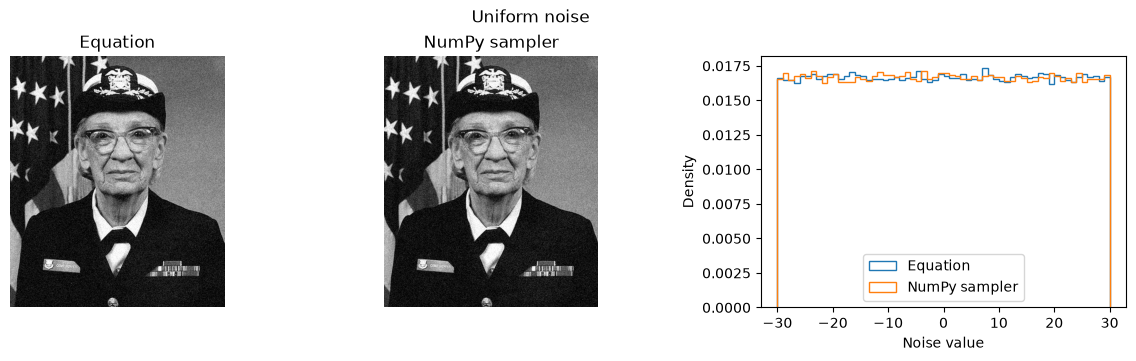

In [3]:
# Question 1
low, high = -30, 30
uniform = low + (high - low) * rng.random(shape)
compare_noise("Uniform noise", uniform, rng.uniform(low, high, shape))

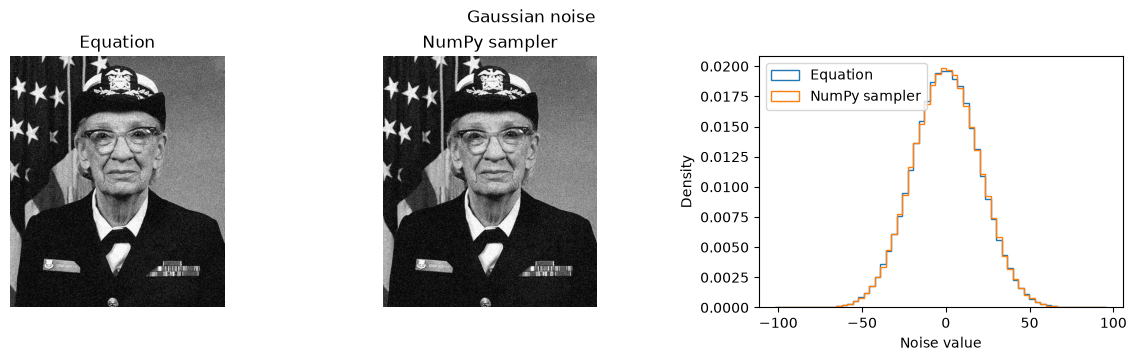

In [4]:
# Question 2
mean, sigma = 0, 20
u1, u2 = 1 - rng.random(shape), rng.random(shape)
gaussian = mean + sigma * np.sqrt(-2 * np.log(u1)) * np.cos(2 * np.pi * u2)
compare_noise("Gaussian noise", gaussian, rng.normal(mean, sigma, shape))

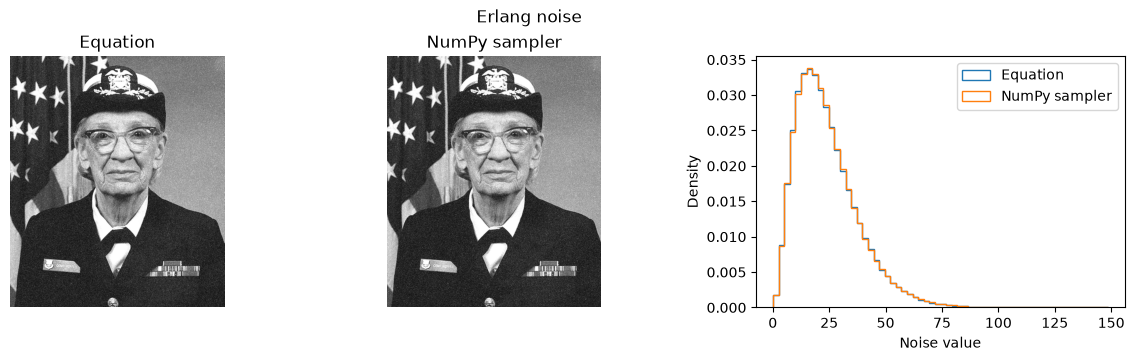

In [5]:
# Question 3
order, scale = 3, 8
erlang = -scale * np.log1p(-rng.random((order, *shape))).sum(axis=0)
compare_noise("Erlang noise", erlang, rng.gamma(order, scale, shape))

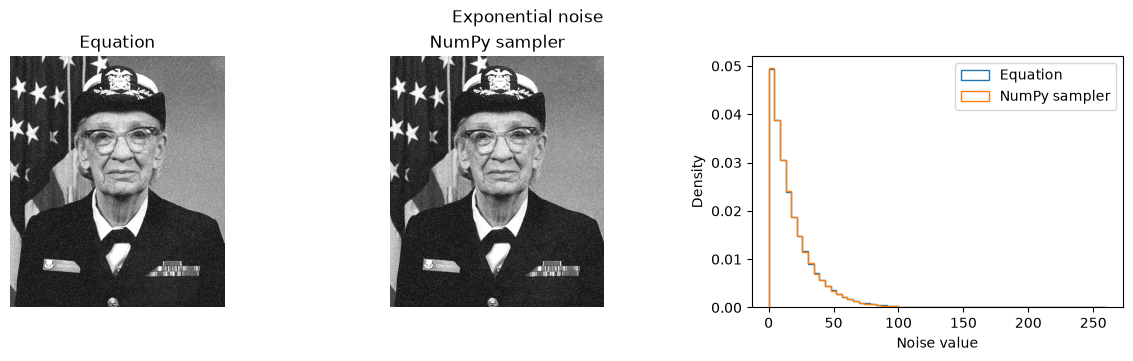

In [6]:
# Question 4
scale = 18
exponential = -scale * np.log1p(-rng.random(shape))
compare_noise("Exponential noise", exponential, rng.exponential(scale, shape))

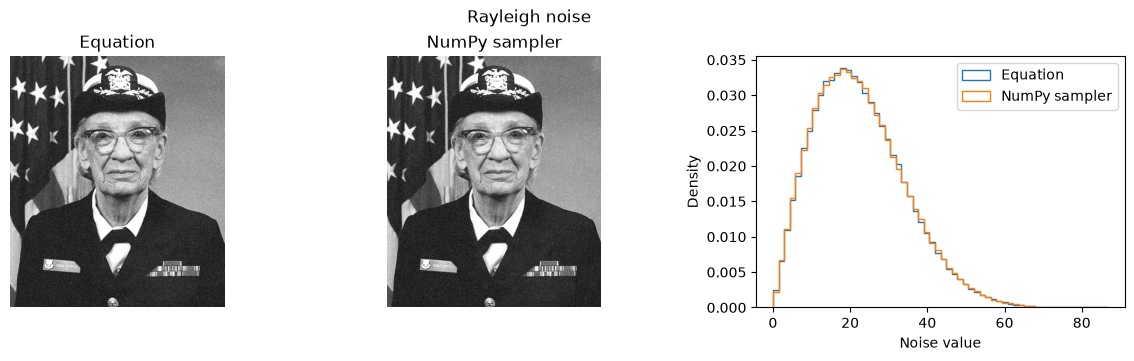

In [7]:
# Question 5
scale = 18
rayleigh = scale * np.sqrt(-2 * np.log1p(-rng.random(shape)))
compare_noise("Rayleigh noise", rayleigh, rng.rayleigh(scale, shape))